## Movement Artifacts
This notebook will exist to turn accelerometer and gyroscopic data into a single, usable dataframe that will flag sections of time where participant movement is too high.

### Files Used
- `data-files\2.1_G1_biometrics.csv` -> Contains phase markers
- `data-files\2.1_G1_ground_truth_AX.csv` -> force in x-direction in g-force units
- `data-files\2.1_G1_ground_truth_AY.csv` -> force in y-direction in g-force units
- `data-files\2.1_G1_ground_truth_AZ.csv` -> force in z-direction in g-force units
- `data-files\2.1_G1_ground_truth_GX.csv` -> x-rotational velocity in degrees/second
- `data-files\2.1_G1_ground_truth_GY.csv` -> y-rotational velocity in degrees/second
- `data-files\2.1_G1_ground_truth_GZ.csv` -> z-rotational velocity in degrees/second

### Important Data Processing Steps To Note
**1. Accelerometer and gyroscope axes are combined row by row, not joined on timestamp.** *(Code: "Data Quality Checks" section.)*
- All six axis files have 127,193 rows (25 Hz, ~84.8 min). There are no gaps (the largest step between samples is 47ms), no missing values, and `DataReliability` is 100 throughout.
- Each row is the same sample across the three axis files. `LocalTimestamp` matches exactly except for 4 rows in GY/GZ (rows 97165–97168), which differ from AX by under 1ms, a rounding difference. Joining exactly on timestamp would have dropped those rows, so the axes are aligned by row position. `load_axes()` asserts that the row counts match and that timestamps never differ by more than `MAX_TIMESTAMP_MISMATCH_S` (5ms).
- No samples are removed or filtered at any point in this notebook.

**2. Magnitude is the Euclidean norm, √(x² + y² + z²).**
- `accel_mag` (g) includes gravity, so a still device should read 1g, not 0.
- `gyro_mag` (deg/s) is about 0 at rest no matter how the device is facing, so it directly measures rotation.

**3. Phases are assigned from the biometrics file with a backward as-of match.** *(Code: "Attaching Experiment Phases" section.)*
- Each motion sample takes the most recent `event_marker` at or before its `LocalTimestamp`.
- The motion recording starts 5.3 seconds before the first marker. Those 134 samples are labeled `unlabeled`.
- Sub-phases are **not** collapsed: `task_1_1`, `prs_1_PRS-SHORT-3-HardToBeBored` and the like are their own phases. `subject_idle` occurs many times and is grouped under one name in the per-phase box plot and table.

**4. At rest, acceleration magnitude depends on device orientation, so movement is measured with a rolling standard deviation.** *(Code: "Orientation Dependence Of Acceleration Magnitude" and "Sensitivity To The Calm-Block Cut-Offs" sections.)*
- *Observation:* at rest the magnitude sits at ~1.078g for most of the session but drops to ~1.061–1.066g during the task_1/prs_1 and task_2/prs_2 blocks, even though rotation is at its lowest then.
- *Check:* the recording is split into 5-second blocks, keeping only calm ones (mean gyro < 1 deg/s and accel std < 0.004g; 687 of 1,018 blocks). A task block runs from the first `task_N` marker to the last `prs_N` marker.

  | Period | Avg AX | Avg AY | Avg AZ | Magnitude | Tilt vs. first period |
  |---|---|---|---|---|---|
  | Before task 1 (0–28 min) | −0.96 | −0.42 | +0.23 | 1.080 | 0° |
  | task_1 / prs_1 (28–39 min) | −0.58 | −0.83 | +0.33 | 1.066 | 31° |
  | Between tasks (40–61 min) | −0.87 | −0.53 | +0.31 | 1.078 | 8° |
  | task_2 / prs_2 (61–70 min) | −0.55 | −0.87 | +0.24 | 1.061 | 33° |
  | After task 2 (72–85 min) | −0.93 | −0.50 | +0.21 | 1.078 | 5° |

  - During the task blocks the device was held at a different, steady angle: gravity shifts from mostly X to mostly Y (a ~31–33° tilt), and it shifts back when each block ends. The changes line up with the large movement bursts at each transition (see "Largest Movement Bursts"). Participants can move their hands freely but are told to keep still, so this looks like a change in held posture, not ongoing movement.
  - Across calm blocks, magnitude correlates −0.97 with AX and +0.98 with AY. A perfect accelerometer would read 1g in every orientation, with no correlation.
  - Fitting a constant offset and scale to each axis brings every calm period to 1.000g (std 0.0006g, down from 0.0073g), and the step disappears.
  - *Cut-off sensitivity:* the calm-block cut-offs were picked by eye from the per-phase summary and are not proposed movement thresholds. Across every combination tested, from the strictest (112 blocks) to no filtering at all (1,018 blocks), the correlation with AX stays at −0.97 to −0.98, and task blocks read 0.014–0.015g lower than the rest. The result does not depend on the cut-offs.
- *Alternatives ruled out:* a real sustained acceleration (an extra 0.015g for ~10 minutes would mean steadily speeding up in one direction the whole time), and temperature drift (it would be gradual, not a step that reverses exactly when orientation reverses).
- *Conclusion:* the accelerometer has small per-axis offset/scale errors, so its resting magnitude changes with orientation. Measuring acceleration movement as distance from 1g or from the session median would label calm, steadily held postures as movement. The by-phase analysis therefore uses the **rolling standard deviation** of `accel_mag` (`accel_std_roll`), which only measures change within a window and ignores a steady offset.
- *Caveat:* the calm orientations cover only a narrow arc (mostly tilting between X and Y), so the fitted per-axis offsets and scales are not uniquely determined and **must not be used as a calibration**. A real calibration would need the session's `_info.json` or a recording of the device held still in six orientations.

**5. Smoothing and display choices.**
- Rolling statistics use a centered window of `ROLLING_WINDOW_S` = 5 s (125 samples). The first and last 2.5 s of the recording have no rolling value.
- Rotational velocity is plotted on log axes because it spans ~0.1–150 deg/s with a long right tail. This affects display only; no values are transformed. In the over-time plot, raw gyro values are clipped at 0.01 deg/s **for display only**, so that zero readings can appear on the log axis.

**6. Movement bursts are dropped; everything else is kept.** *(Code: "Movement Mask For HRV Cleaning" section.)*
- A sample is dropped if the 5 s rolling mean of `gyro_mag` is above `BURST_GYRO_DEG_S` (30 deg/s), or if it falls within `DROP_PADDING_S` (5 s) of such a stretch. Gyro is used rather than acceleration because it isn't affected by orientation (step 4).
- With these settings, the four transition bursts are dropped (85.6 s, 1.68% of the recording, all in `sart_2`, `sart_3`, `sart_5` and `sart_6`). Lowering the threshold to 10 deg/s adds only two more bursts (2.5% dropped with 5 s padding), so the result is not very sensitive to the exact threshold.
- Both values are provisional. The mask is saved to `processed-data/2.1_G1_movement_mask.csv` (`LocalTimestamp`, `EmotiBitTimestamp`, `keep`) for use in `999_hrv-cleaning.ipynb`.

### Global Variables & Imports

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("../data-files")
FILE_PREFIX = "2.1_G1_ground_truth_"
BIOMETRICS_FILE = DATA_DIR / "2.1_G1_biometrics.csv"

ACCEL_TAGS = ["AX", "AY", "AZ"]
GYRO_TAGS = ["GX", "GY", "GZ"]

SAMPLE_RATE_HZ = 25 # EmotiBit IMU samples every ~40ms
ROLLING_WINDOW_S = 5 # Smoothing window for the over-time plots
MAX_TIMESTAMP_MISMATCH_S = 0.005 # Axes are sampled together, so rows should line up well within one sample period

ACCEL_COLOR = "#2a78d6"
GYRO_COLOR = "#eb6834"

### Combining The Axes Into Magnitudes
The three axis files for each sensor have the same number of rows, and each row is the same sample (timestamps match to within 1ms, which is a rounding difference in 4 rows of GY/GZ). So the axes can be combined row by row instead of joined on timestamp.

Magnitude is the Euclidean norm of the three axes: $\sqrt{x^2 + y^2 + z^2}$
- **Acceleration magnitude** includes gravity, so a device sitting still reads about 1g, not 0. Movement shows up as deviation from that resting level.
- **Rotational velocity magnitude** is about 0 deg/s at rest, so its value is a direct measure of how fast the device is turning.

In [2]:
def load_axes(tags):
    """Load the per-axis files for one sensor and return them side by side, aligned row-by-row."""
    frames = [pd.read_csv(DATA_DIR / f"{FILE_PREFIX}{tag}.csv") for tag in tags]
    base = frames[0]

    for tag, df in zip(tags[1:], frames[1:]):
        assert len(df) == len(base), f"{tag} has {len(df)} rows, expected {len(base)}"
        mismatch = (df["LocalTimestamp"] - base["LocalTimestamp"]).abs().max()
        assert mismatch < MAX_TIMESTAMP_MISMATCH_S, f"{tag} timestamps drift from {tags[0]} by up to {mismatch:.4f}s"

    combined = base[["LocalTimestamp", "EmotiBitTimestamp"]].copy()
    for tag, df in zip(tags, frames):
        combined[tag] = df[tag].values
    return combined

def to_magnitude(axes_df, tags, name):
    """Collapse the x/y/z columns into a single magnitude column."""
    out = axes_df[["LocalTimestamp", "EmotiBitTimestamp"]].copy()
    out[name] = np.sqrt((axes_df[tags] ** 2).sum(axis=1))
    return out

accel_df = to_magnitude(load_axes(ACCEL_TAGS), ACCEL_TAGS, "accel_mag")   # g
gyro_df = to_magnitude(load_axes(GYRO_TAGS), GYRO_TAGS, "gyro_mag")       # deg/s

accel_df.head()

,LocalTimestamp,EmotiBitTimestamp,accel_mag
0,1.757035e+09,2099282.000,1.070333
1,1.757035e+09,2099322.500,1.080830
2,1.757035e+09,2099363.000,1.074466
3,1.757035e+09,2099402.667,1.060136
4,1.757035e+09,2099442.333,1.078275


In [3]:
gyro_df.head()

,LocalTimestamp,EmotiBitTimestamp,gyro_mag
0,1.757035e+09,2099282.000,1.566905
1,1.757035e+09,2099322.500,4.803314
2,1.757035e+09,2099363.000,3.992555
3,1.757035e+09,2099402.667,3.191016
4,1.757035e+09,2099442.333,2.228626


In [4]:
pd.concat([accel_df["accel_mag"], gyro_df["gyro_mag"]], axis=1).describe(percentiles=[.01, .05, .25, .5, .75, .95, .99, .999])

,accel_mag,gyro_mag
count,127193.000000,127193.000000
mean,1.074854,1.492083
std,0.013531,6.419725
min,0.754461,0.000000
1%,1.054954,0.129638
5%,1.060260,0.216375
25%,1.067146,0.396693
50%,1.077480,0.583199
75%,1.080752,0.930388
95%,1.085583,2.933015


### Data Quality Checks
Checks the raw axis files for missing values, timing gaps, reliability flags, and the rows where timestamps differ between axes.

In [5]:
raw = {tag: pd.read_csv(DATA_DIR / f"{FILE_PREFIX}{tag}.csv") for tag in ACCEL_TAGS + GYRO_TAGS}
base_ts = raw["AX"]["LocalTimestamp"]
sample_dt = base_ts.diff().dropna()

quality = pd.DataFrame({
    tag: {
        "rows": len(df),
        "missing_values": int(df[tag].isna().sum()),
        "reliability_values": sorted(df["DataReliability"].unique().tolist()),
        "rows_with_ts_mismatch_vs_AX": int((df["LocalTimestamp"] != base_ts).sum()),
        "max_ts_mismatch_ms": round((df["LocalTimestamp"] - base_ts).abs().max() * 1000, 3),
    }
    for tag, df in raw.items()
}).T
print(f"Duration: {(base_ts.iloc[-1] - base_ts.iloc[0]) / 60:.2f} min")
print(f"Sample interval: median {sample_dt.median() * 1000:.1f}ms, min {sample_dt.min() * 1000:.1f}ms, max {sample_dt.max() * 1000:.1f}ms")
print(f"GY rows with mismatched timestamps: {np.flatnonzero(raw['GY']['LocalTimestamp'] != base_ts).tolist()}")
quality

Duration: 84.81 min
Sample interval: median 40.0ms, min 33.0ms, max 47.0ms
GY rows with mismatched timestamps: [97165, 97166, 97167, 97168]


,rows,missing_values,reliability_values,rows_with_ts_mismatch_vs_AX,max_ts_mismatch_ms
AX,127193,0,[100],0,0.0
AY,127193,0,[100],0,0.0
AZ,127193,0,[100],0,0.0
GX,127193,0,[100],0,0.0
GY,127193,0,[100],4,1.0
GZ,127193,0,[100],4,1.0


### Attaching Experiment Phases
Phase markers only exist in the biometrics file, so each motion sample gets the most recent marker at or before its timestamp. Sub-phases are kept as their own phases (e.g. `task_1_1`, `prs_1_PRS-SHORT-3-HardToBeBored`). Samples before the first marker are labeled `unlabeled`.

In [6]:
phases = (
    pd.read_csv(BIOMETRICS_FILE, usecols=["timestamp_unix", "event_marker"])
    .dropna()
    .sort_values("timestamp_unix")
    .rename(columns={"event_marker": "phase"})
)

movement_df = accel_df.copy()
movement_df["gyro_mag"] = gyro_df["gyro_mag"].values # Same samples as accel_df, row for row (see load_axes)
movement_df = pd.merge_asof(
    movement_df, phases[["timestamp_unix", "phase"]],
    left_on="LocalTimestamp", right_on="timestamp_unix", direction="backward",
).drop(columns="timestamp_unix")
movement_df["phase"] = movement_df["phase"].fillna("unlabeled")
movement_df["minutes"] = (movement_df["LocalTimestamp"] - movement_df["LocalTimestamp"].iloc[0]) / 60

# One row per continuous run of a phase, used to shade the over-time plots
run_id = (movement_df["phase"] != movement_df["phase"].shift()).cumsum()
phase_segments = movement_df.groupby(run_id).agg(
    phase=("phase", "first"), start=("minutes", "first"), end=("minutes", "last")
).reset_index(drop=True)

phase_segments

,phase,start,end
0,unlabeled,0.000000,0.088668
1,startup,0.089334,0.408638
2,biometric_baseline,0.409305,2.408912
3,subject_idle,2.409579,5.405315
4,ser_baseline,5.405981,8.171514
5,subject_idle,8.172181,8.339500
6,sart_1,8.340166,15.702621
7,practice_stressor_test,15.703288,16.646099
8,subject_idle,16.646766,17.995082
9,stressor_test_1,17.995749,23.073093


In [7]:
first_marker_s = phases["timestamp_unix"].iloc[0] - movement_df["LocalTimestamp"].iloc[0]
print(f"Motion recording starts {first_marker_s:.1f}s before the first phase marker "
      f"({(movement_df['phase'] == 'unlabeled').sum()} samples labeled 'unlabeled')")

Motion recording starts 5.3s before the first phase marker (134 samples labeled 'unlabeled')


### Movement Over Time
Thin lines are the raw 25 Hz samples, and the darker line is a rolling mean over the smoothing window. Rotational velocity is on a log scale because it spans about 0.1 to 150 deg/s. Shaded bands mark the experiment phases, and phases longer than 2 minutes are labeled.

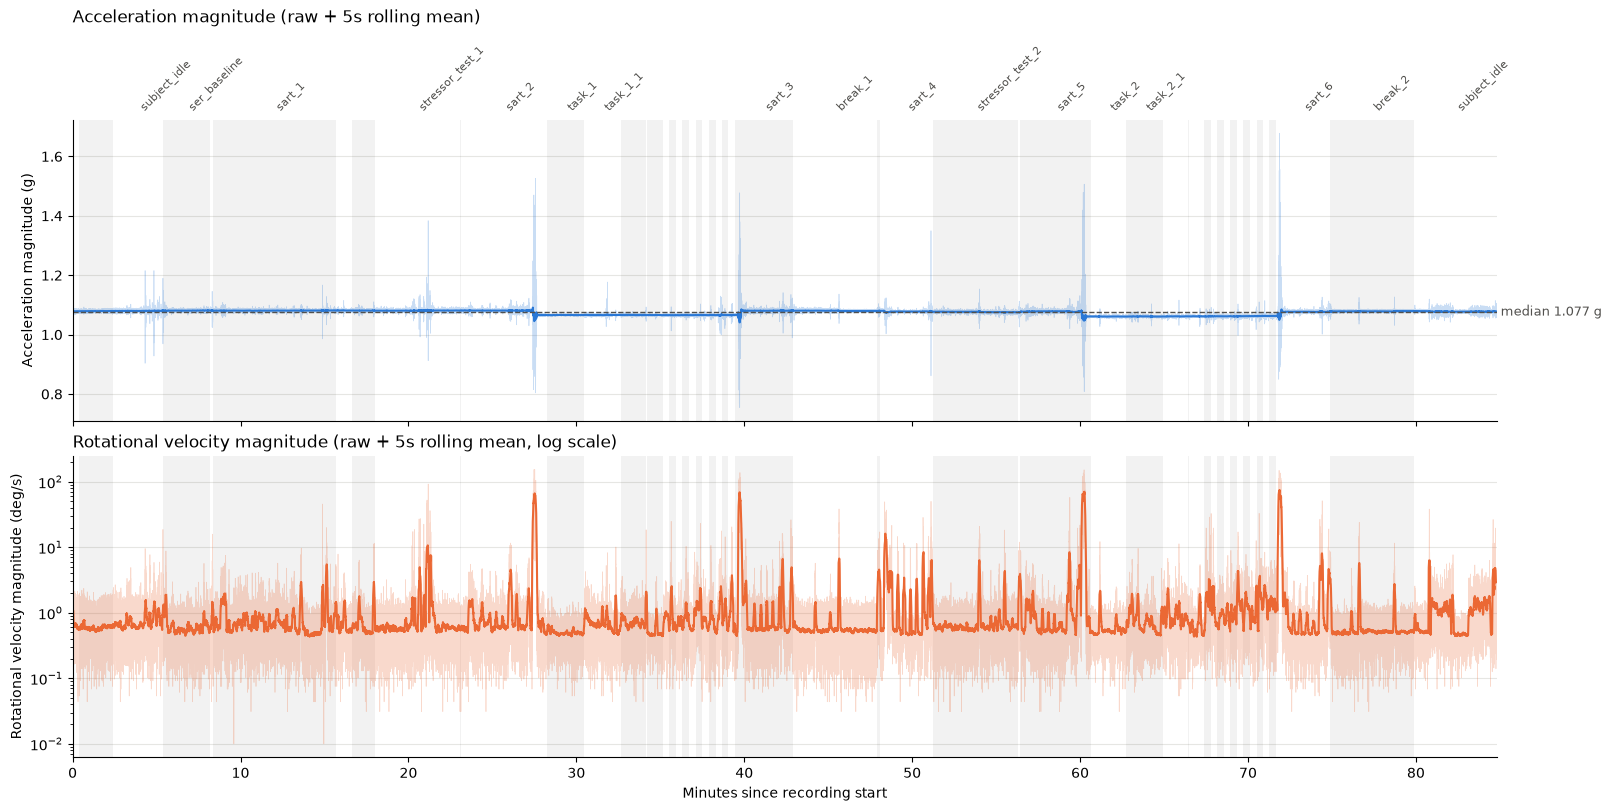

In [8]:
window = ROLLING_WINDOW_S * SAMPLE_RATE_HZ
accel_rest = movement_df["accel_mag"].median()

fig, (ax_a, ax_g) = plt.subplots(2, 1, figsize=(16, 8), sharex=True, constrained_layout=True)

for ax in (ax_a, ax_g):
    for i, seg in phase_segments.iterrows():
        if i % 2 == 0:
            ax.axvspan(seg["start"], seg["end"], color="#000000", alpha=0.05, lw=0)
    ax.grid(axis="y", color="#e6e6e3", lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

ax_a.plot(movement_df["minutes"], movement_df["accel_mag"], color=ACCEL_COLOR, alpha=0.25, lw=0.5)
ax_a.plot(movement_df["minutes"], movement_df["accel_mag"].rolling(window, center=True).mean(), color=ACCEL_COLOR, lw=1.5)
ax_a.axhline(accel_rest, color="#52514e", lw=1, ls="--")
ax_a.text(movement_df["minutes"].iloc[-1], accel_rest, f" median {accel_rest:.3f} g", va="center", color="#52514e", fontsize=9)
ax_a.set_ylabel("Acceleration magnitude (g)")
ax_a.set_title(f"Acceleration magnitude (raw + {ROLLING_WINDOW_S}s rolling mean)", loc="left", pad=70)

ax_g.plot(movement_df["minutes"], movement_df["gyro_mag"].clip(lower=0.01), color=GYRO_COLOR, alpha=0.25, lw=0.5)
ax_g.plot(movement_df["minutes"], movement_df["gyro_mag"].rolling(window, center=True).mean(), color=GYRO_COLOR, lw=1.5)
ax_g.set_yscale("log")
ax_g.set_ylabel("Rotational velocity magnitude (deg/s)")
ax_g.set_xlabel("Minutes since recording start")
ax_g.set_title(f"Rotational velocity magnitude (raw + {ROLLING_WINDOW_S}s rolling mean, log scale)", loc="left")

for _, seg in phase_segments.iterrows():
    if seg["end"] - seg["start"] >= 2:
        ax_a.text((seg["start"] + seg["end"]) / 2, 1.02, seg["phase"], transform=ax_a.get_xaxis_transform(),
                  rotation=45, ha="left", va="bottom", fontsize=8, color="#52514e")

ax_g.set_xlim(0, movement_df["minutes"].iloc[-1])
plt.show()

### Largest Movement Bursts
A burst is a continuous stretch where the rolling-mean rotational velocity is above `BURST_GYRO_DEG_S`. Each burst is listed with its peak values and the phase active at its peak. This threshold is only for finding the largest events to describe; it is **not** a proposed movement threshold.

In [9]:
BURST_GYRO_DEG_S = 30

gyro_roll = movement_df["gyro_mag"].rolling(window, center=True).mean()
in_burst = gyro_roll > BURST_GYRO_DEG_S
burst_id = (in_burst != in_burst.shift()).cumsum()[in_burst]

burst_rows = []
for _, idx in burst_id.groupby(burst_id).groups.items():
    seg = movement_df.loc[idx]
    peak = seg["gyro_mag"].idxmax()
    burst_rows.append({
        "start_min": seg["minutes"].iloc[0], "end_min": seg["minutes"].iloc[-1],
        "phase_at_peak": movement_df.at[peak, "phase"],
        "peak_gyro": seg["gyro_mag"].max(), "peak_gyro_roll": gyro_roll[idx].max(),
        "accel_min": seg["accel_mag"].min(), "accel_max": seg["accel_mag"].max(),
    })
pd.DataFrame(burst_rows).round(3)

,start_min,end_min,phase_at_peak,peak_gyro,peak_gyro_roll,accel_min,accel_max
0,27.422,27.613,sart_2,153.626,66.434,0.804,1.526
1,39.655,39.805,sart_3,137.788,68.950,0.754,1.477
2,60.096,60.308,sart_5,151.737,70.311,0.808,1.506
3,71.796,72.001,sart_6,148.950,73.957,0.850,1.678


### Distribution Of Movement
Histograms of every sample for each sensor. Rotational velocity uses log-spaced bins on a log axis because of its long right tail.

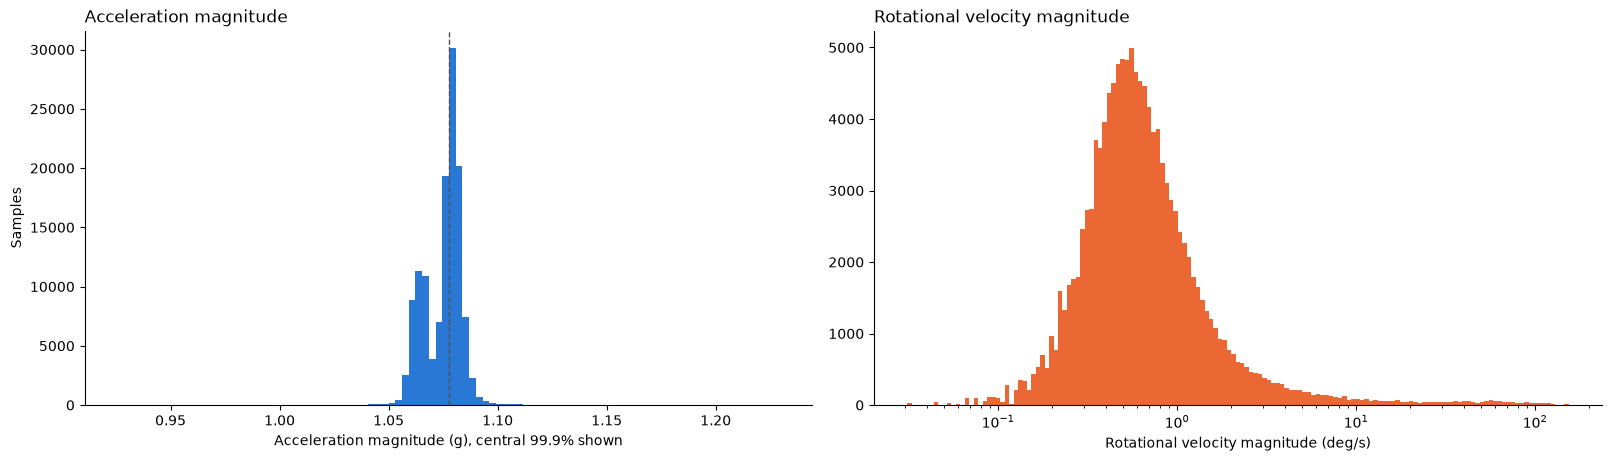

In [10]:
fig, (ax_a, ax_g) = plt.subplots(1, 2, figsize=(16, 4.5), constrained_layout=True)

ax_a.hist(movement_df["accel_mag"], bins=300, color=ACCEL_COLOR)
ax_a.axvline(accel_rest, color="#52514e", lw=1, ls="--")
ax_a.set_xlim(movement_df["accel_mag"].quantile(0.0005), movement_df["accel_mag"].quantile(0.9995))
ax_a.set_xlabel("Acceleration magnitude (g), central 99.9% shown")
ax_a.set_ylabel("Samples")
ax_a.set_title("Acceleration magnitude", loc="left")

gyro_pos = movement_df["gyro_mag"][movement_df["gyro_mag"] > 0]
ax_g.hist(gyro_pos, bins=np.logspace(np.log10(gyro_pos.min()), np.log10(gyro_pos.max()), 150), color=GYRO_COLOR)
ax_g.set_xscale("log")
ax_g.set_xlabel("Rotational velocity magnitude (deg/s)")
ax_g.set_title("Rotational velocity magnitude", loc="left")

for ax in (ax_a, ax_g):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
plt.show()

### Movement By Phase
Each value is one rolling window, grouped by phase. Phases are listed in the order they first occur.

For acceleration, the value is the **rolling standard deviation** of the magnitude rather than its distance from the overall median. The resting magnitude shifts from about 1.077g to about 1.063g during the physical tasks (visible as the step in the over-time plot) because each axis has a small calibration error, so the magnitude depends on device orientation. Distance from one global median would label those calm stretches as movement. Rolling standard deviation only measures change within the window, so orientation doesn't affect it.

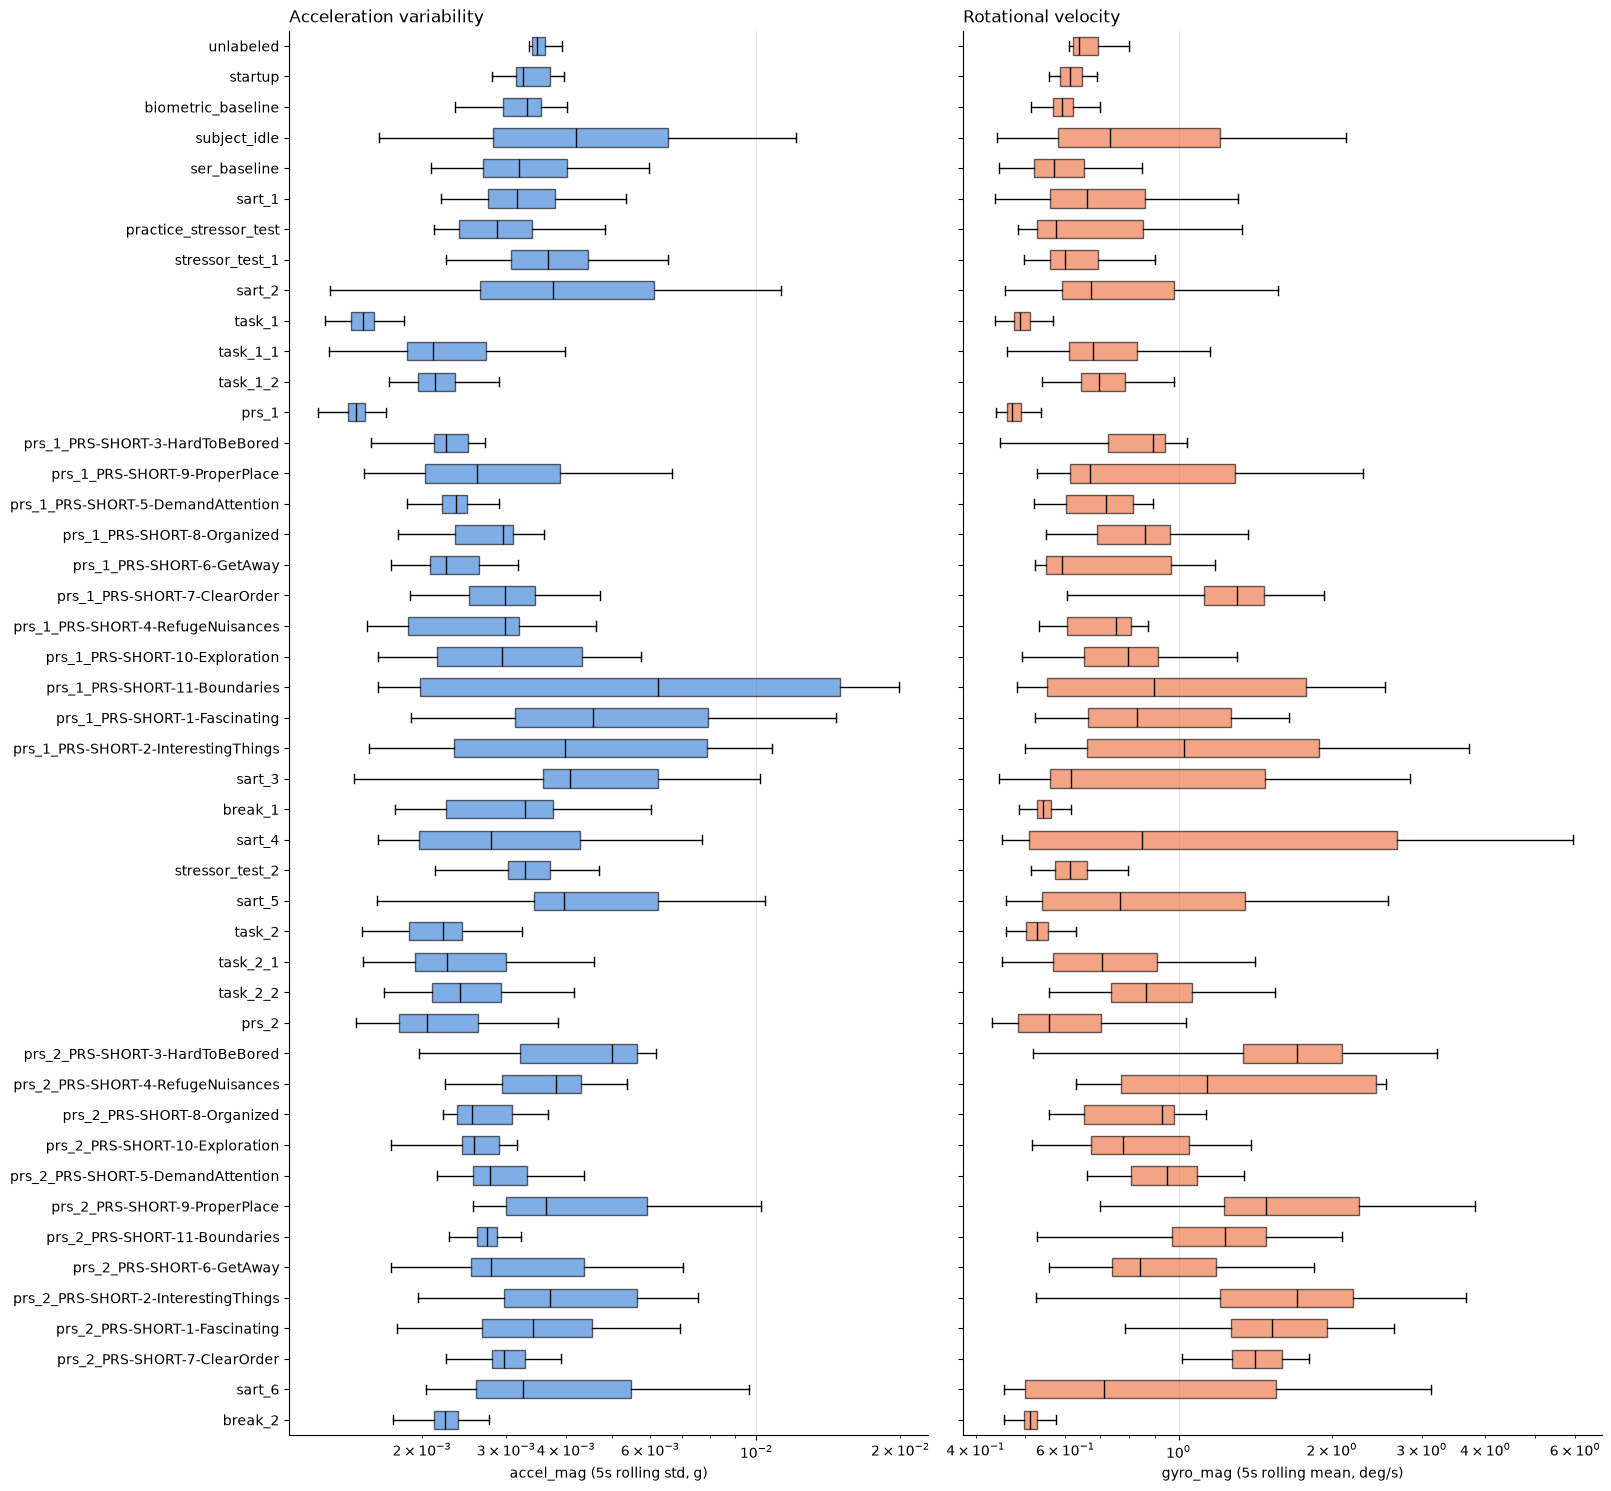

In [11]:
movement_df["accel_std_roll"] = movement_df["accel_mag"].rolling(window, center=True).std()
movement_df["gyro_roll"] = movement_df["gyro_mag"].rolling(window, center=True).mean()

phase_order = list(dict.fromkeys(movement_df["phase"]))
by_phase = [movement_df.loc[movement_df["phase"] == p] for p in phase_order]

fig, (ax_a, ax_g) = plt.subplots(1, 2, figsize=(16, 0.3 * len(phase_order) + 1), sharey=True, constrained_layout=True)
box_style = dict(orientation="horizontal", showfliers=False, widths=0.6, patch_artist=True, medianprops=dict(color="#0b0b0b"))

bp = ax_a.boxplot([d["accel_std_roll"].dropna() for d in by_phase], **box_style)
for patch in bp["boxes"]:
    patch.set(facecolor=ACCEL_COLOR, alpha=0.6)
ax_a.set_xscale("log")
ax_a.set_xlabel(f"accel_mag ({ROLLING_WINDOW_S}s rolling std, g)")
ax_a.set_title("Acceleration variability", loc="left")

bp = ax_g.boxplot([d["gyro_roll"].dropna() for d in by_phase], **box_style)
for patch in bp["boxes"]:
    patch.set(facecolor=GYRO_COLOR, alpha=0.6)
ax_g.set_xscale("log")
ax_g.set_xlabel(f"gyro_mag ({ROLLING_WINDOW_S}s rolling mean, deg/s)")
ax_g.set_title("Rotational velocity", loc="left")

ax_a.set_yticks(range(1, len(phase_order) + 1), phase_order)
ax_a.invert_yaxis()
for ax in (ax_a, ax_g):
    ax.grid(axis="x", color="#e6e6e3", lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
plt.show()

In [12]:
phase_summary = movement_df.groupby("phase", sort=False).agg(
    minutes=("minutes", lambda m: len(m) / SAMPLE_RATE_HZ / 60),
    accel_std_median=("accel_std_roll", "median"),
    accel_std_p95=("accel_std_roll", lambda s: s.quantile(0.95)),
    gyro_median=("gyro_roll", "median"),
    gyro_p95=("gyro_roll", lambda s: s.quantile(0.95)),
    gyro_max=("gyro_mag", "max"),
).round(3)
phase_summary

,minutes,accel_std_median,accel_std_p95,gyro_median,gyro_p95,gyro_max
phase,,,,,,
unlabeled,0.089,0.003,0.005,0.637,0.971,5.778
startup,0.320,0.003,0.004,0.614,0.673,2.147
biometric_baseline,2.000,0.003,0.004,0.592,0.661,2.352
subject_idle,9.949,0.004,0.009,0.734,2.719,38.190
ser_baseline,2.766,0.003,0.007,0.571,1.031,8.768
sart_1,7.362,0.003,0.007,0.661,1.698,45.642
practice_stressor_test,0.943,0.003,0.006,0.576,1.382,7.844
stressor_test_1,5.077,0.004,0.017,0.599,4.643,92.216
sart_2,5.092,0.004,0.028,0.674,12.369,153.626


### Orientation Dependence Of Acceleration Magnitude
Supports processing step 4. The recording is split into non-overlapping `BLOCK_S` blocks, and only calm blocks are kept (mean `gyro_mag` < `STILL_GYRO_MAX` and `accel_mag` std < `STILL_ACCEL_STD_MAX`). These cut-offs were picked by eye from the per-phase summary to keep reasonably calm blocks, and they are **not** proposed movement thresholds. The sensitivity check below shows the result doesn't depend on them.

Calm blocks are grouped into periods by whether they fall in a task/PRS block (from the first `task_N` marker to the last `prs_N` marker) or between them. For each period, the table shows the average gravity direction (mean of each axis) and the average magnitude. The tilt is the angle between each period's mean gravity vector and the first period's.

In [13]:
BLOCK_S = 5
STILL_GYRO_MAX = 1.0      # deg/s
STILL_ACCEL_STD_MAX = 0.004 # g

accel_axes = load_axes(ACCEL_TAGS)
blocks_src = movement_df[["minutes", "phase", "accel_mag", "gyro_mag"]].join(accel_axes[ACCEL_TAGS])
blocks_src["block"] = (blocks_src["minutes"] * 60 // BLOCK_S).astype(int)
blocks = blocks_src.groupby("block").agg(
    start_min=("minutes", "first"), phase=("phase", "first"),
    AX=("AX", "mean"), AY=("AY", "mean"), AZ=("AZ", "mean"),
    accel_mag=("accel_mag", "mean"), accel_std=("accel_mag", "std"), gyro_mean=("gyro_mag", "mean"),
)
# A task block runs from the first task_N marker to the last prs_N marker, including the short subject_idle between them
blocks["task_block"] = False
for n in (1, 2):
    span = movement_df.loc[movement_df["phase"].str.match(rf"^(task|prs)_{n}"), "minutes"]
    blocks.loc[blocks["start_min"].between(span.min(), span.max()), "task_block"] = True
blocks["period"] = (blocks["task_block"] != blocks["task_block"].shift()).cumsum()

def calm(b, gyro_max=STILL_GYRO_MAX, std_max=STILL_ACCEL_STD_MAX):
    return b[(b["gyro_mean"] < gyro_max) & (b["accel_std"] < std_max)]

still = calm(blocks)
print(f"Calm blocks: {len(still)} of {len(blocks)}")

periods = still.groupby("period").agg(
    task_block=("task_block", "first"), start_min=("start_min", "min"), end_min=("start_min", "max"),
    blocks=("accel_mag", "size"), AX=("AX", "mean"), AY=("AY", "mean"), AZ=("AZ", "mean"), accel_mag=("accel_mag", "mean"),
)
g = periods[ACCEL_TAGS].to_numpy()
cos = (g @ g[0]) / (np.linalg.norm(g, axis=1) * np.linalg.norm(g[0]))
periods["tilt_vs_first_deg"] = np.degrees(np.arccos(cos.clip(-1, 1)))
periods.round(4)

Calm blocks: 687 of 1018


,task_block,start_min,end_min,blocks,AX,AY,AZ,accel_mag,tilt_vs_first_deg
period,,,,,,,,,
1,False,0.0833,28.1673,225,-0.9592,-0.4195,0.2325,1.0801,0.0000
2,True,28.2506,39.4172,110,-0.5787,-0.8340,0.3250,1.0659,30.9283
3,False,39.5005,60.5833,161,-0.8723,-0.5276,0.3064,1.0781,8.4207
4,True,60.6673,70.3336,87,-0.5514,-0.8749,0.2373,1.0614,33.2958
5,False,72.4172,84.5003,104,-0.9255,-0.5039,0.2087,1.0781,5.0136


In [14]:
print("Correlation of accel_mag with each axis across calm blocks (0 expected for a perfect sensor):")
print(still[ACCEL_TAGS + ["accel_mag"]].corr()["accel_mag"].drop("accel_mag").round(3).to_string())

# Fit a constant offset and scale per axis so calm blocks read 1g: k*x^2 + c*x summed over axes = 1 (axis-aligned ellipsoid)
A = still[ACCEL_TAGS].to_numpy()
coef, *_ = np.linalg.lstsq(np.c_[A ** 2, A], np.ones(len(A)), rcond=None)
k, c = coef[:3], coef[3:]
offset = -c / (2 * k)
scale = np.sqrt(k / (1 + np.sum(k * offset ** 2)))
corrected = np.sqrt((((A - offset) * scale) ** 2).sum(axis=1))

print(f"\nFitted offsets (g): {offset.round(4)}   scales: {scale.round(4)}  (illustrative only, NOT a calibration)")
print(f"Raw magnitude of calm blocks:       mean {still['accel_mag'].mean():.4f}  std {still['accel_mag'].std():.4f}")
print(f"Corrected magnitude of calm blocks: mean {corrected.mean():.4f}  std {corrected.std():.4f}")
pd.Series(corrected, index=still.index).groupby(still["period"]).mean().round(4).rename("corrected_mag_by_period")

Correlation of accel_mag with each axis across calm blocks (0 expected for a perfect sensor):
AX   -0.973
AY    0.979
AZ   -0.185

Fitted offsets (g): [ 0.0522 -0.0581  0.0202]   scales: [0.8925 0.999  0.9461]  (illustrative only, NOT a calibration)
Raw magnitude of calm blocks:       mean 1.0747  std 0.0073
Corrected magnitude of calm blocks: mean 1.0000  std 0.0006


period
1    1.0002
2    1.0005
3    1.0001
4    0.9994
5    0.9995
Name: corrected_mag_by_period, dtype: float64

#### Sensitivity To The Calm-Block Cut-Offs
Repeats the comparison for a range of cut-offs, including no filtering at all. If the orientation effect were an artifact of the cut-offs, the correlation and the gap between task and non-task blocks would change.

In [15]:
sensitivity = []
for gyro_max in [0.5, 0.75, 1.0, 2.0, np.inf]:
    for std_max in [0.003, 0.004, 0.006, np.inf]:
        b = calm(blocks, gyro_max, std_max)
        sensitivity.append({
            "gyro_max": gyro_max, "accel_std_max": std_max, "blocks": len(b),
            "corr_mag_AX": b["accel_mag"].corr(b["AX"]),
            "mag_task_blocks": b.loc[b["task_block"], "accel_mag"].mean(),
            "mag_other_blocks": b.loc[~b["task_block"], "accel_mag"].mean(),
        })
sensitivity = pd.DataFrame(sensitivity)
sensitivity["gap"] = sensitivity["mag_other_blocks"] - sensitivity["mag_task_blocks"]
sensitivity.round(4)

,gyro_max,accel_std_max,blocks,corr_mag_AX,mag_task_blocks,mag_other_blocks,gap
0,0.50,0.003,112,-0.9813,1.0643,1.0780,0.0138
1,0.50,0.004,114,-0.9797,1.0643,1.0781,0.0138
2,0.50,0.006,114,-0.9797,1.0643,1.0781,0.0138
3,0.50,inf,114,-0.9797,1.0643,1.0781,0.0138
4,0.75,0.003,403,-0.9812,1.0641,1.0789,0.0148
5,0.75,0.004,603,-0.9704,1.0640,1.0791,0.0150
6,0.75,0.006,653,-0.9698,1.0640,1.0792,0.0151
7,0.75,inf,659,-0.9698,1.0640,1.0792,0.0151
8,1.00,0.003,448,-0.9813,1.0640,1.0787,0.0147
9,1.00,0.004,687,-0.9732,1.0639,1.0790,0.0151


### Observations
Each observation names the section whose output supports it.
- **Data quality** *(Data Quality Checks)*: all six axis files have 127,193 samples at 25 Hz (84.8 min). There are no gaps (sample interval 33–47ms) and no missing values, and `DataReliability` is 100 throughout.
- **Most of the session is still** *(summary statistics table, Distribution Of Movement)*: median rotational velocity is ~0.6 deg/s, 95% of samples are under ~3 deg/s, and 98% of acceleration-magnitude samples are within ~0.02g of the median. The distributions have one main peak with a long right tail, not separate clusters, so low/medium/high levels won't fall out of natural gaps in the data.
- **Movement comes in short bursts, not sustained periods** *(summary statistics table, Movement Over Time)*: the tail (99th percentile ~22 deg/s, max ~154 deg/s) comes from brief spikes.
- **The four biggest bursts are at the transitions into and out of the physical tasks** *(Largest Movement Bursts)*: at ~27.4, ~39.7, ~60.1 and ~71.8 min, each lasting under 15 seconds. Rotation peaks at 138–154 deg/s, and acceleration magnitude swings between 0.75g and 1.68g. They fall within `sart_2`, `sart_3`, `sart_5` and `sart_6`, next to the task blocks, which is why those phases have the widest spread and highest p95 gyro values.
- **The physical tasks themselves are among the calmest phases** *(Movement By Phase)*: the parent markers `task_1` and `prs_1` (before any sub-phase starts) have the lowest values in the whole session on both sensors. The `task_*_*` sub-phases are a bit more active but still low.
- **The PRS questionnaire items involve small, frequent rotations** *(Movement By Phase)*, especially in `prs_2` (item medians ~0.8 to 1.7 deg/s, compared with ~0.5 to 0.6 at rest). That fits answering on a device or turning the head between items. Individual items are only ~22 seconds each, so their per-item statistics are based on few windows.
- **The resting acceleration magnitude depends on orientation** *(Orientation Dependence Of Acceleration Magnitude, Sensitivity To The Calm-Block Cut-Offs)*: it steps from ~1.078g to ~1.061–1.066g during the task_1/prs_1 and task_2/prs_2 blocks, when the device is held ~31–33° differently. That is a change in how the device is facing, not movement, so any accelerometer threshold should use a local measure (rolling std, or deviation from a rolling baseline) rather than distance from a fixed 1g or the session median. See processing step 4 at the top.
- **Gyro is the cleaner movement signal** *(Movement Over Time, Orientation Dependence)*: it sits near 0 at rest no matter how the device is facing, and it rises during every burst that also shows up in the accelerometer.

### Movement Mask For HRV Cleaning
The participant is still for most of the session, so the cleaning rule is to **drop movement bursts and keep everything else**.
- A burst uses the same definition as in "Largest Movement Bursts": the `ROLLING_WINDOW_S` rolling mean of `gyro_mag` is above `BURST_GYRO_DEG_S`. Rotational velocity is used because it isn't affected by device orientation (see processing step 4).
- Each burst is widened by `DROP_PADDING_S` on both sides. The raw spikes start before and end after the stretch where the rolling mean is above the threshold, and the PPG/heart-rate signal needs a few beats to settle after movement.

The output has one row per motion sample (25 Hz) with `LocalTimestamp` (Unix seconds, the same clock as `timestamp_unix` in the biometrics file) and `keep`. It is saved to `MASK_OUTPUT_FILE` for use in `999_hrv-cleaning.ipynb`.

**`BURST_GYRO_DEG_S` and `DROP_PADDING_S` are provisional.** The table below shows how much data each combination would drop.

In [16]:
DROP_PADDING_S = 5
MASK_OUTPUT_FILE = Path("../processed-data/2.1_G1_movement_mask.csv")

def burst_drop_mask(gyro_threshold, padding_s):
    """True for samples inside a burst (rolling-mean gyro above threshold) or within padding_s of one."""
    in_burst = gyro_roll > gyro_threshold
    pad = int(padding_s * SAMPLE_RATE_HZ)
    return in_burst.astype(int).rolling(2 * pad + 1, center=True, min_periods=1).max().astype(bool)

drop_options = []
for gyro_threshold in [10, 20, 30, 50]:
    for padding_s in [0, 5, 10]:
        drop = burst_drop_mask(gyro_threshold, padding_s)
        drop_options.append({
            "gyro_threshold": gyro_threshold, "padding_s": padding_s,
            "bursts": int((drop & ~drop.shift(fill_value=False)).sum()),
            "dropped_s": drop.sum() / SAMPLE_RATE_HZ,
            "dropped_pct": 100 * drop.mean(),
        })
pd.DataFrame(drop_options).round(2)

,gyro_threshold,padding_s,bursts,dropped_s,dropped_pct
0,10,0,6,68.28,1.34
1,10,5,6,128.28,2.52
2,10,10,6,188.28,3.70
3,20,0,4,53.00,1.04
4,20,5,4,93.00,1.83
5,20,10,4,133.00,2.61
6,30,0,4,45.60,0.90
7,30,5,4,85.60,1.68
8,30,10,4,125.60,2.47
9,50,0,4,31.92,0.63


In [17]:
drop = burst_drop_mask(BURST_GYRO_DEG_S, DROP_PADDING_S)
movement_mask = pd.DataFrame({
    "LocalTimestamp": movement_df["LocalTimestamp"],
    "EmotiBitTimestamp": movement_df["EmotiBitTimestamp"],
    "keep": ~drop,
})

print(f"Dropped {drop.sum()} of {len(drop)} samples ({drop.sum() / SAMPLE_RATE_HZ:.1f}s, {100 * drop.mean():.2f}%)")
print("Dropped seconds by phase:")
print((drop.groupby(movement_df["phase"], sort=False).sum() / SAMPLE_RATE_HZ).loc[lambda s: s > 0].round(1).to_string())

MASK_OUTPUT_FILE.parent.mkdir(exist_ok=True)
movement_mask.to_csv(MASK_OUTPUT_FILE, index=False)
movement_mask.head()

Dropped 2140 of 127193 samples (85.6s, 1.68%)
Dropped seconds by phase:
phase
sart_2    21.5
sart_3    19.0
sart_5    22.7
sart_6    22.4


,LocalTimestamp,EmotiBitTimestamp,keep
0,1.757035e+09,2099282.000,True
1,1.757035e+09,2099322.500,True
2,1.757035e+09,2099363.000,True
3,1.757035e+09,2099402.667,True
4,1.757035e+09,2099442.333,True
